In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report,confusion_matrix
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense,Flatten
from tensorflow.keras.optimizers import Adam

In [7]:
df=pd.read_csv('creditcard.csv')
print(data.shape)

(284807, 31)


In [8]:
df=df.drop('Time',axis=1)

In [9]:
normal_data=df[df['Class']==0]
fraud_data=df[df['Class']==1]

In [10]:
x_normal=normal_data.drop('Class',axis=1)
y_normal=normal_data['Class']

In [13]:
x_train_normal,x_test_normal=train_test_split(x_normal,test_size=0.2,random_state=42)
x_test=pd.concat([x_test_normal,fraud_data.drop('Class',axis=1)])
y_test=np.concatenate([np.zeros(len(x_test_normal)),np.ones(len(fraud_data))])

In [14]:
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train_normal)
x_test=scaler.transform(x_test)

In [15]:
model=Sequential([
    Input(shape=x_train.shape[1:]),
    Dense(16,activation='relu'),
    Dense(8,activation='relu'),
    Dense(16,activation='relu'),
    Dense(x_train.shape[1],activation='linear')
])

In [16]:
model.compile(optimizer='adam',loss='mse',metrics=['accuracy'])

In [18]:
history = model.fit(
    x_train, x_train, 
    epochs=10, 
    batch_size=256, 
    validation_split=0.1,
)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.2005 - loss: 0.8123 - val_accuracy: 0.3064 - val_loss: 0.6689
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3520 - loss: 0.5884 - val_accuracy: 0.3847 - val_loss: 0.5609
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3882 - loss: 0.5331 - val_accuracy: 0.3834 - val_loss: 0.5340
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3874 - loss: 0.5072 - val_accuracy: 0.3821 - val_loss: 0.5036
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3828 - loss: 0.4885 - val_accuracy: 0.3802 - val_loss: 0.4883
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3802 - loss: 0.4757 - val_accuracy: 0.3824 - val_loss: 0.4788
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3813 - loss: 0.4663 - val_accuracy: 0.3871 - val_loss: 0.4686
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3879 - loss: 0.4567 - val_accuracy: 0.

In [19]:
reconstructions=model.predict(x_test)
mse=np.mean(np.power(x_test-reconstructions,2),axis=1)

1793/1793 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [24]:
train_reconstructions=model.predict(x_train)
train_mse=np.mean(np.power(x_train-train_reconstructions,2),axis=1)
threshold=np.percentile(train_mse,95)
print(f"calculated fraud Threshold:{threshold:.4f}")

7108/7108 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step
calculated fraud Threshold:0.9787


In [25]:
predictions=(mse>threshold).astype(int)
print("\n--- Classificatoin Report ---")
print(classification_report(y_test,predictions,target_names=['Normal (0)','Fraud (1)']))


--- Classificatoin Report ---
              precision    recall  f1-score   support

  Normal (0)       1.00      0.95      0.97     56863
   Fraud (1)       0.12      0.84      0.21       492

    accuracy                           0.95     57355
   macro avg       0.56      0.89      0.59     57355
weighted avg       0.99      0.95      0.97     57355



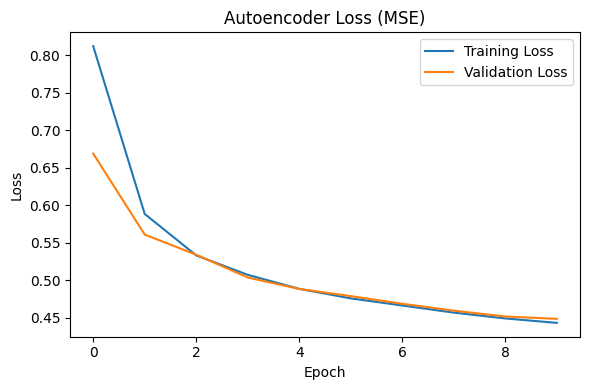

In [26]:
plt.figure(figsize=(6, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()

Loading dataset...

Training autoencoder on normal transactions...
Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.1706 - loss: 0.7698 - val_accuracy: 0.2315 - val_loss: 0.6607
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2585 - loss: 0.5980 - val_accuracy: 0.2817 - val_loss: 0.5807
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3010 - loss: 0.5486 - val_accuracy: 0.3083 - val_loss: 0.5484
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3168 - loss: 0.5289 - val_accuracy: 0.3174 - val_loss: 0.5339
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3228 - loss: 0.5175 - val_accuracy: 0.3330 - val_loss: 0.5225
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3211 - loss: 0.5062 - val_accuracy: 0.3197 - val_loss: 0.5132
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.3183 - loss: 0.4976 - val_accuracy: 0.3216 - val_loss: 0.5053
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━

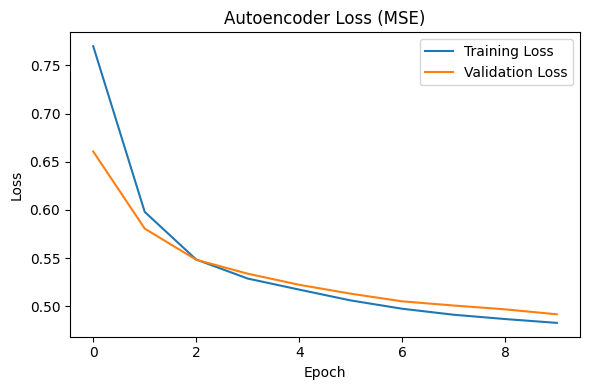

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# ==========================================
# STEP 1: PREPARE THE DATA
# ==========================================
print("Loading dataset...")
df = pd.read_csv('creditcard.csv')

# Drop the 'Time' column as it is not helpful for spending patterns
df = df.drop(['Time'], axis=1)

# Separate into Normal (Class 0) and Fraud (Class 1)
normal_data = df[df['Class'] == 0]
fraud_data = df[df['Class'] == 1]

# Separate features (X) and labels (y) for normal data
X_normal = normal_data.drop('Class', axis=1)
y_normal = normal_data['Class']

# Split normal data into training (80%) and testing (20%)
X_train_normal, X_test_normal = train_test_split(X_normal, test_size=0.2, random_state=42)

# Create the final test exam by combining the normal test data with ALL the fraud data
X_test = pd.concat([X_test_normal, fraud_data.drop('Class', axis=1)])
y_test = np.concatenate([np.zeros(len(X_test_normal)), np.ones(len(fraud_data))])

# Scale the data (Fit scaler ONLY on normal training data)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_normal)
X_test = scaler.transform(X_test)

# ==========================================
# STEP 2: DEFINE THE AUTOENCODER (Dense Layers)
# ==========================================
input_dim = X_train.shape[1] 

model = Sequential([
    Input(shape=(input_dim,)),
    # Encoder
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),  # Bottleneck
    # Decoder
    Dense(16, activation='relu'),
    Dense(input_dim, activation='linear')
])

# ==========================================
# STEP 3: TRAIN THE MODEL
# ==========================================
model.compile(optimizer='adam', loss='mse', metrics=['accuracy'])

print("\nTraining autoencoder on normal transactions...")
# Pass X_train as both the input AND the target
history = model.fit(
    X_train, X_train, 
    epochs=10, 
    batch_size=256, 
    validation_split=0.1,
    verbose=1
)

# ==========================================
# STEP 4: THRESHOLDING & DETECTION 
# ==========================================
print("\nCalculating reconstruction errors...")

# 1. Have model predict on the mixed test set
reconstructions = model.predict(X_test)

# 2. Calculate the Mean Squared Error (MSE) for every test sample
mse = np.mean(np.power(X_test - reconstructions, 2), axis=1)

# 3. Calculate the threshold (95th percentile of the training error)
train_reconstructions = model.predict(X_train)
train_mse = np.mean(np.power(X_train - train_reconstructions, 2), axis=1)
threshold = np.percentile(train_mse, 95)
print(f"Calculated Fraud Threshold: {threshold:.4f}")

# 4. Flag as Fraud (1) if error is above threshold, else Normal (0)
predictions = (mse > threshold).astype(int)

print("\n--- Classification Report ---")
print(classification_report(y_test, predictions, target_names=['Normal (0)', 'Fraud (1)']))

# Plot the training loss
plt.figure(figsize=(6, 4))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Loss (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()